# 🧪 Model Testing — Fake Product Review Detection

This notebook provides a **comprehensive test suite** for the trained model. It goes beyond basic accuracy to give you deep insight into how the model performs.

## What This Notebook Covers

| Section | Description |
|---------|-------------|
| 1 | Load the saved model & vectorizer |
| 2 | Test set evaluation (accuracy, precision, recall, F1) |
| 3 | Detailed confusion matrix analysis |
| 4 | Per-class performance breakdown |
| 5 | Confidence distribution analysis |
| 6 | Error analysis — inspect misclassified reviews |
| 7 | Performance by review length |
| 8 | Performance by product category |
| 9 | Most important features (words) for classification |
| 10 | Custom review testing |
| 11 | Final summary report |

### Prerequisites

Run `train.ipynb` (or `python src/train.py`) first to generate the model files.

---

## 1. Setup — Import Libraries & Load Model

In [1]:
import os
import re
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    classification_report, confusion_matrix, roc_curve, auc,
    precision_recall_curve, average_precision_score,
)
import joblib

warnings.filterwarnings('ignore')
%matplotlib inline
plt.style.use('seaborn-v0_8-whitegrid')

print("✅ Libraries imported!")

✅ Libraries imported!


In [2]:
# ── Configuration ──
RANDOM_STATE = 42
TEST_SIZE = 0.2
LABEL_MAP = {'CG': 1, 'OR': 0}
LABEL_NAME_MAP = {1: 'Fake', 0: 'Genuine'}

# ── Paths ──
PROJECT_DIR = os.path.abspath("..")
DATA_PATH = os.path.join(PROJECT_DIR, "data", "fake_reviews_dataset.csv")
MODEL_PATH = os.path.join(PROJECT_DIR, "models", "logistic_regression_model.pkl")
VECTORIZER_PATH = os.path.join(PROJECT_DIR, "models", "tfidf_vectorizer.pkl")

# ── Text cleaning (must match training) ──
def clean_text(text):
    if not isinstance(text, str):
        return ""
    text = text.lower()
    text = re.sub(r'http\S+|www\.\S+', '', text)
    text = re.sub(r'<.*?>', '', text)
    text = re.sub(r'[^a-z0-9\s]', '', text)
    text = re.sub(r'\s+', ' ', text).strip()
    return text

print("✅ Configuration set!")

✅ Configuration set!


In [3]:
# ── Load model & vectorizer ──
print("📦 Loading model and vectorizer...")
model = joblib.load(MODEL_PATH)
vectorizer = joblib.load(VECTORIZER_PATH)
print(f"   Model: {type(model).__name__} (C={model.C})")
print(f"   Vectorizer: {len(vectorizer.vocabulary_):,} features")
print("✅ Loaded successfully!")

📦 Loading model and vectorizer...
   Model: LogisticRegression (C=1.0)
   Vectorizer: 15,000 features
✅ Loaded successfully!


## 2. Recreate the Test Set

We reload and preprocess the data, then split it using the **same `random_state=42`** to get the exact same test set used during training.

In [4]:
# ── Load & preprocess (same as training) ──
print("📂 Loading dataset...")
df = pd.read_csv(DATA_PATH)
df = df[['category', 'rating', 'label', 'text_']].copy()
df = df.dropna(subset=['text_', 'label'])
df = df.drop_duplicates(subset=['text_'], keep='first')
df = df[df['label'].isin(LABEL_MAP.keys())]
df['text_'] = df['text_'].apply(clean_text)
df = df[df['text_'].str.strip() != '']
df['label'] = df['label'].map(LABEL_MAP)
df['label_name'] = df['label'].map(LABEL_NAME_MAP)
df = df.reset_index(drop=True)

# ── Split (same random_state as training) ──
X = df['text_']
y = df['label']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=TEST_SIZE, random_state=RANDOM_STATE, stratify=y
)

# Get the test set's metadata (category, rating) for deeper analysis
test_indices = X_test.index
df_test = df.loc[test_indices].copy()

# ── Transform test data ──
X_test_tfidf = vectorizer.transform(X_test)

print(f"\n✅ Test set recreated: {len(X_test):,} reviews")
print(f"   Fake:    {(y_test == 1).sum():,}")
print(f"   Genuine: {(y_test == 0).sum():,}")

📂 Loading dataset...

✅ Test set recreated: 8,083 reviews
   Fake:    4,040
   Genuine: 4,043


---

## 3. Overall Model Performance

Let's evaluate the model on the test set and see all the key metrics.

In [5]:
# ── Predictions ──
y_pred = model.predict(X_test_tfidf)
y_proba = model.predict_proba(X_test_tfidf)

# ── Metrics ──
accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)

print("╔══════════════════════════════════════════╗")
print("║     📊 MODEL PERFORMANCE SUMMARY         ║")
print("╠══════════════════════════════════════════╣")
print(f"║  Accuracy:    {accuracy:.4f}  ({accuracy*100:.2f}%)       ║")
print(f"║  Precision:   {precision:.4f}  ({precision*100:.2f}%)       ║")
print(f"║  Recall:      {recall:.4f}  ({recall*100:.2f}%)       ║")
print(f"║  F1-Score:    {f1:.4f}  ({f1*100:.2f}%)       ║")
print("╚══════════════════════════════════════════╝")

╔══════════════════════════════════════════╗
║     📊 MODEL PERFORMANCE SUMMARY         ║
╠══════════════════════════════════════════╣
║  Accuracy:    0.9393  (93.93%)       ║
║  Precision:   0.9455  (94.55%)       ║
║  Recall:      0.9322  (93.22%)       ║
║  F1-Score:    0.9388  (93.88%)       ║
╚══════════════════════════════════════════╝


In [6]:
# ── Full Classification Report ──
target_names = ['Genuine (OR)', 'Fake (CG)']
print("📋 Detailed Classification Report:\n")
print(classification_report(y_test, y_pred, target_names=target_names))

📋 Detailed Classification Report:

              precision    recall  f1-score   support

Genuine (OR)       0.93      0.95      0.94      4043
   Fake (CG)       0.95      0.93      0.94      4040

    accuracy                           0.94      8083
   macro avg       0.94      0.94      0.94      8083
weighted avg       0.94      0.94      0.94      8083



---

## 4. Confusion Matrix — Detailed Analysis

The confusion matrix shows us exactly where the model gets things right and wrong.

| | Predicted Genuine | Predicted Fake |
|---|---|---|
| **Actual Genuine** | True Negative (TN) ✅ | False Positive (FP) ❌ |
| **Actual Fake** | False Negative (FN) ❌ | True Positive (TP) ✅ |

- **False Positive (FP)**: Genuine review wrongly flagged as Fake — could frustrate honest reviewers
- **False Negative (FN)**: Fake review not caught — the worse outcome for review integrity

In [7]:
cm = confusion_matrix(y_test, y_pred)
tn, fp, fn, tp = cm.ravel()

# ── Print breakdown ──
print("📊 Confusion Matrix Breakdown:\n")
print(f"   True Negatives  (Genuine → Genuine): {tn:,}  ✅")
print(f"   False Positives (Genuine → Fake):    {fp:,}   ❌  (innocent reviews falsely flagged)")
print(f"   False Negatives (Fake → Genuine):    {fn:,}   ❌  (fake reviews that slipped through)")
print(f"   True Positives  (Fake → Fake):       {tp:,}  ✅")

total_errors = fp + fn
total_correct = tn + tp
print(f"\n   Total correct:  {total_correct:,} / {len(y_test):,} ({total_correct/len(y_test)*100:.1f}%)")
print(f"   Total errors:   {total_errors:,} / {len(y_test):,} ({total_errors/len(y_test)*100:.1f}%)")
print(f"   Error ratio FP:FN = {fp}:{fn}")

📊 Confusion Matrix Breakdown:

   True Negatives  (Genuine → Genuine): 3,826  ✅
   False Positives (Genuine → Fake):    217   ❌  (innocent reviews falsely flagged)
   False Negatives (Fake → Genuine):    274   ❌  (fake reviews that slipped through)
   True Positives  (Fake → Fake):       3,766  ✅

   Total correct:  7,592 / 8,083 (93.9%)
   Total errors:   491 / 8,083 (6.1%)
   Error ratio FP:FN = 217:274


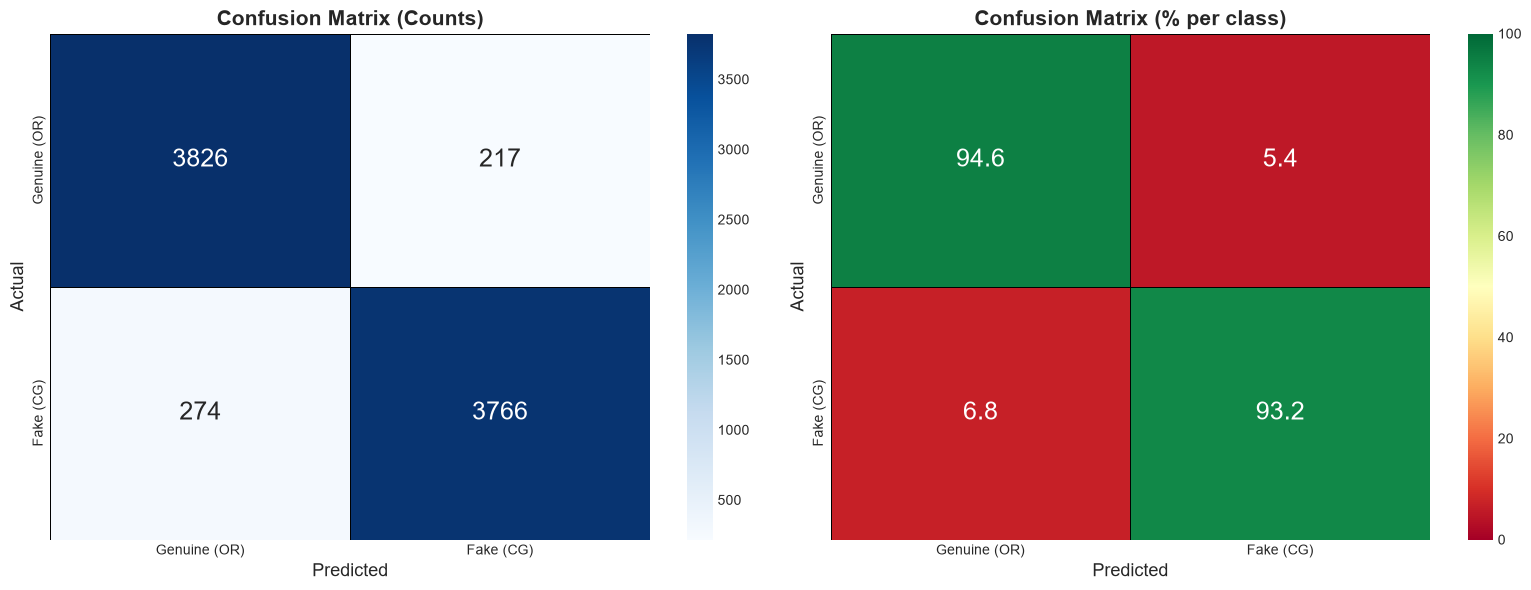

In [8]:
# ── Visualization: Confusion Matrix (counts + percentages) ──
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Counts
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=target_names, yticklabels=target_names,
            ax=axes[0], annot_kws={'size': 18}, linewidths=0.5, linecolor='black')
axes[0].set_xlabel('Predicted', fontsize=13)
axes[0].set_ylabel('Actual', fontsize=13)
axes[0].set_title('Confusion Matrix (Counts)', fontsize=15, fontweight='bold')

# Percentages
cm_pct = cm.astype('float') / cm.sum(axis=1)[:, np.newaxis] * 100
sns.heatmap(cm_pct, annot=True, fmt='.1f', cmap='RdYlGn',
            xticklabels=target_names, yticklabels=target_names,
            ax=axes[1], annot_kws={'size': 18}, linewidths=0.5, linecolor='black',
            vmin=0, vmax=100)
axes[1].set_xlabel('Predicted', fontsize=13)
axes[1].set_ylabel('Actual', fontsize=13)
axes[1].set_title('Confusion Matrix (% per class)', fontsize=15, fontweight='bold')

plt.tight_layout()
plt.show()

---

## 5. Confidence Distribution Analysis

How confident is the model in its predictions? Ideally, we want:
- **Correct predictions** → high confidence (>80%)
- **Wrong predictions** → lower confidence (model is unsure)

In [9]:
# ── Calculate confidence for each prediction ──
df_test = df_test.copy()
df_test['predicted'] = y_pred
df_test['predicted_name'] = df_test['predicted'].map(LABEL_NAME_MAP)
df_test['correct'] = (y_test.values == y_pred)
df_test['confidence'] = np.max(y_proba, axis=1) * 100
df_test['fake_prob'] = y_proba[:, 1] * 100
df_test['genuine_prob'] = y_proba[:, 0] * 100

print("📊 Confidence Statistics:\n")
print(f"   Overall mean confidence:  {df_test['confidence'].mean():.1f}%")
print(f"   Correct predictions:      {df_test[df_test['correct']]['confidence'].mean():.1f}% avg confidence")
print(f"   Wrong predictions:        {df_test[~df_test['correct']]['confidence'].mean():.1f}% avg confidence")

📊 Confidence Statistics:

   Overall mean confidence:  86.3%
   Correct predictions:      87.6% avg confidence
   Wrong predictions:        65.6% avg confidence


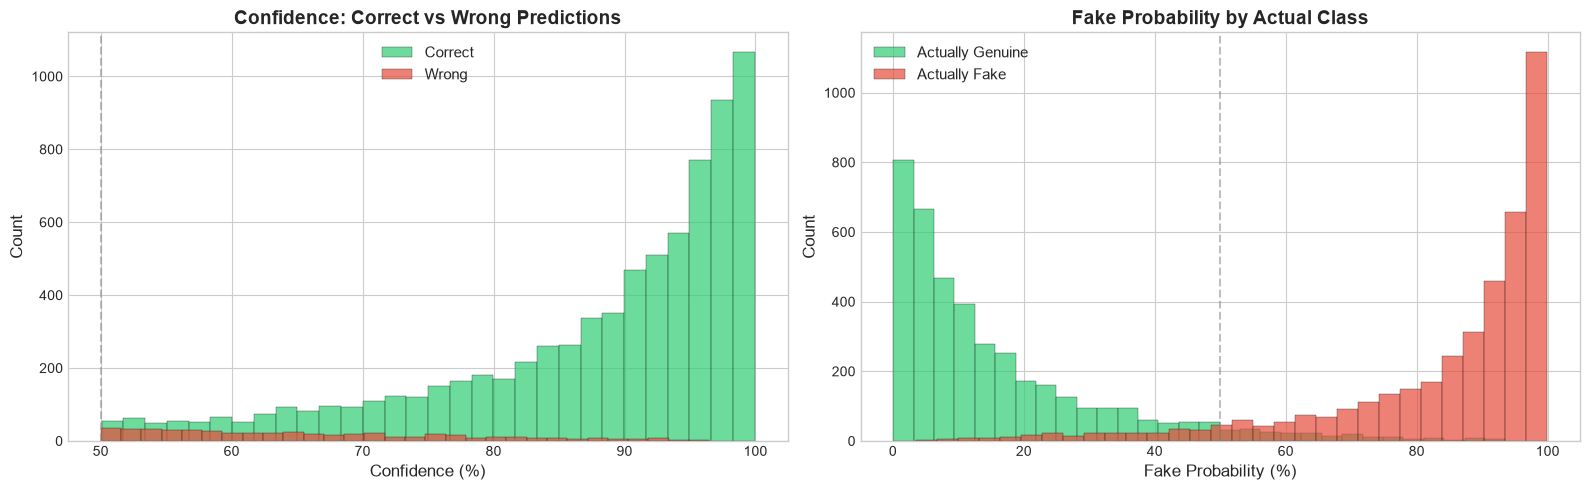

In [10]:
# ── Visualization: Confidence distributions ──
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

# Correct vs Wrong
axes[0].hist(df_test[df_test['correct']]['confidence'], bins=30, alpha=0.7,
             color='#2ecc71', label='Correct', edgecolor='black', linewidth=0.3)
axes[0].hist(df_test[~df_test['correct']]['confidence'], bins=30, alpha=0.7,
             color='#e74c3c', label='Wrong', edgecolor='black', linewidth=0.3)
axes[0].set_title('Confidence: Correct vs Wrong Predictions', fontsize=14, fontweight='bold')
axes[0].set_xlabel('Confidence (%)', fontsize=12)
axes[0].set_ylabel('Count', fontsize=12)
axes[0].legend(fontsize=11)
axes[0].axvline(x=50, color='gray', linestyle='--', alpha=0.5)

# Fake prob distribution by actual class
axes[1].hist(df_test[df_test['label'] == 0]['fake_prob'], bins=30, alpha=0.7,
             color='#2ecc71', label='Actually Genuine', edgecolor='black', linewidth=0.3)
axes[1].hist(df_test[df_test['label'] == 1]['fake_prob'], bins=30, alpha=0.7,
             color='#e74c3c', label='Actually Fake', edgecolor='black', linewidth=0.3)
axes[1].set_title('Fake Probability by Actual Class', fontsize=14, fontweight='bold')
axes[1].set_xlabel('Fake Probability (%)', fontsize=12)
axes[1].set_ylabel('Count', fontsize=12)
axes[1].legend(fontsize=11)
axes[1].axvline(x=50, color='gray', linestyle='--', alpha=0.5, label='Decision boundary')

plt.tight_layout()
plt.show()

---

## 6. ROC Curve & Precision-Recall Curve

These curves show model performance across all possible classification thresholds.

- **ROC Curve**: Plots True Positive Rate vs False Positive Rate. Area Under Curve (AUC) closer to 1.0 is better.
- **Precision-Recall Curve**: Especially useful for imbalanced datasets. Average Precision (AP) closer to 1.0 is better.

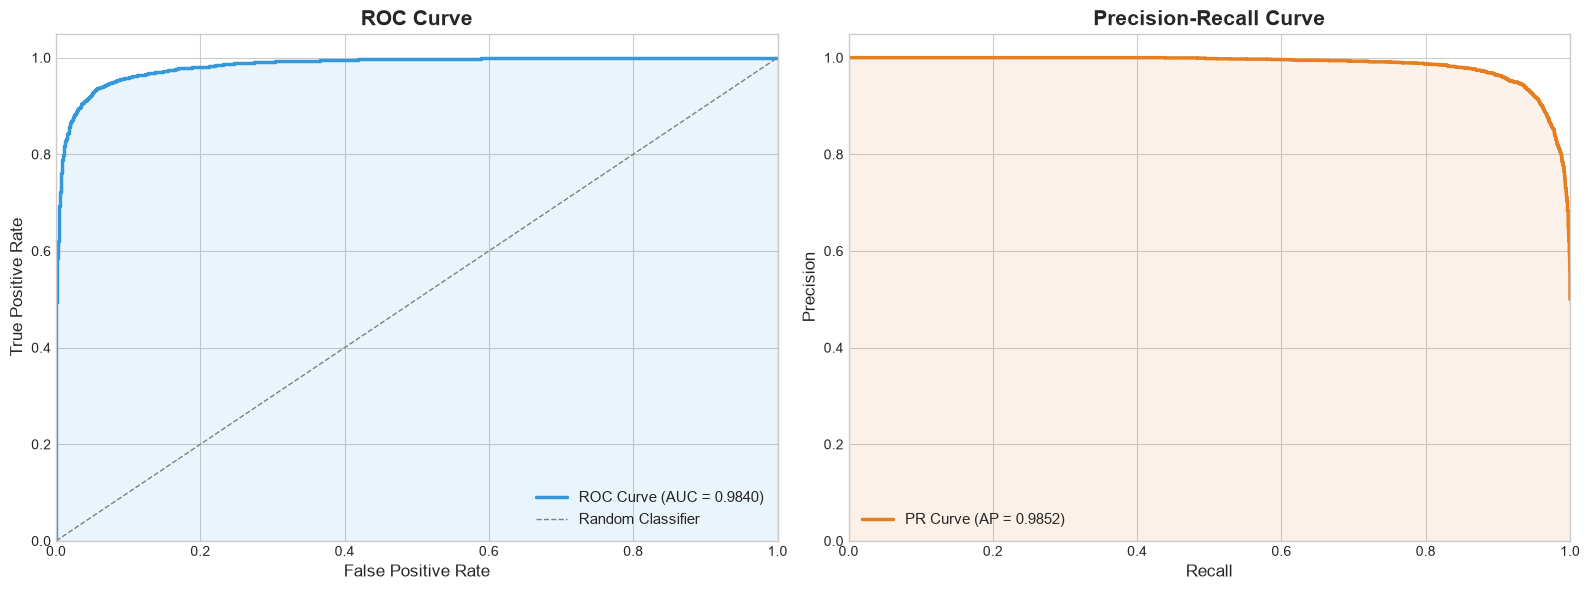


📊 ROC AUC: 0.9840
📊 Average Precision: 0.9852


In [11]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# ── ROC Curve ──
fpr, tpr, thresholds_roc = roc_curve(y_test, y_proba[:, 1])
roc_auc = auc(fpr, tpr)

axes[0].plot(fpr, tpr, color='#3498db', lw=2.5, label=f'ROC Curve (AUC = {roc_auc:.4f})')
axes[0].plot([0, 1], [0, 1], color='gray', linestyle='--', lw=1, label='Random Classifier')
axes[0].fill_between(fpr, tpr, alpha=0.1, color='#3498db')
axes[0].set_xlabel('False Positive Rate', fontsize=12)
axes[0].set_ylabel('True Positive Rate', fontsize=12)
axes[0].set_title('ROC Curve', fontsize=15, fontweight='bold')
axes[0].legend(fontsize=11, loc='lower right')
axes[0].set_xlim([0, 1])
axes[0].set_ylim([0, 1.05])

# ── Precision-Recall Curve ──
prec, rec, thresholds_pr = precision_recall_curve(y_test, y_proba[:, 1])
ap = average_precision_score(y_test, y_proba[:, 1])

axes[1].plot(rec, prec, color='#e67e22', lw=2.5, label=f'PR Curve (AP = {ap:.4f})')
axes[1].fill_between(rec, prec, alpha=0.1, color='#e67e22')
axes[1].set_xlabel('Recall', fontsize=12)
axes[1].set_ylabel('Precision', fontsize=12)
axes[1].set_title('Precision-Recall Curve', fontsize=15, fontweight='bold')
axes[1].legend(fontsize=11, loc='lower left')
axes[1].set_xlim([0, 1])
axes[1].set_ylim([0, 1.05])

plt.tight_layout()
plt.show()

print(f"\n📊 ROC AUC: {roc_auc:.4f}")
print(f"📊 Average Precision: {ap:.4f}")

---

## 7. Error Analysis — Inspecting Misclassified Reviews

Let's look at the reviews the model got **wrong**. This helps us understand the model's limitations.

### 7.1 False Positives — Genuine reviews wrongly flagged as Fake

In [12]:
# ── False Positives (Genuine predicted as Fake) ──
fp_reviews = df_test[(df_test['label'] == 0) & (df_test['predicted'] == 1)].copy()
fp_reviews = fp_reviews.sort_values('confidence', ascending=False)

print(f"🔍 False Positives: {len(fp_reviews)} genuine reviews wrongly flagged as Fake\n")
print("Top 5 most confident False Positives:\n")

for i, (_, row) in enumerate(fp_reviews.head(5).iterrows()):
    print(f"── FP #{i+1} (Fake confidence: {row['fake_prob']:.1f}%) ──")
    print(f"   Category: {row['category']}")
    print(f"   Review:   {row['text_'][:150]}...")
    print()

🔍 False Positives: 217 genuine reviews wrongly flagged as Fake

Top 5 most confident False Positives:

── FP #1 (Fake confidence: 93.5%) ──
   Category: Clothing_Shoes_and_Jewelry_5
   Review:   this shoe is very nice the fit is great i have a wide foot they fit feel wonderful...

── FP #2 (Fake confidence: 92.5%) ──
   Category: Books_5
   Review:   this is the second book in the series and its just as delightful as the first if you love the young adult genre but also love fairytales this one will...

── FP #3 (Fake confidence: 92.2%) ──
   Category: Movies_and_TV_5
   Review:   this is a strong and great movie the acting is well done it is a well made movie...

── FP #4 (Fake confidence: 92.1%) ──
   Category: Clothing_Shoes_and_Jewelry_5
   Review:   the quality is great the color is awesome and the fit is perfect...

── FP #5 (Fake confidence: 91.6%) ──
   Category: Clothing_Shoes_and_Jewelry_5
   Review:   the slippers i bought my granddaughter were too small the exchange could no

### 7.2 False Negatives — Fake reviews that slipped through

In [13]:
# ── False Negatives (Fake predicted as Genuine) ──
fn_reviews = df_test[(df_test['label'] == 1) & (df_test['predicted'] == 0)].copy()
fn_reviews = fn_reviews.sort_values('genuine_prob', ascending=False)

print(f"🔍 False Negatives: {len(fn_reviews)} fake reviews missed by the model\n")
print("Top 5 most confident False Negatives:\n")

for i, (_, row) in enumerate(fn_reviews.head(5).iterrows()):
    print(f"── FN #{i+1} (Genuine confidence: {row['genuine_prob']:.1f}%) ──")
    print(f"   Category: {row['category']}")
    print(f"   Review:   {row['text_'][:150]}...")
    print()

🔍 False Negatives: 274 fake reviews missed by the model

Top 5 most confident False Negatives:

── FN #1 (Genuine confidence: 96.5%) ──
   Category: Tools_and_Home_Improvement_5
   Review:   good package but i hardly noticed it until the night before i got home from work...

── FN #2 (Genuine confidence: 95.5%) ──
   Category: Clothing_Shoes_and_Jewelry_5
   Review:   display your american patriotism in this wallet as well as the other u s...

── FN #3 (Genuine confidence: 94.9%) ──
   Category: Clothing_Shoes_and_Jewelry_5
   Review:   there isnt much room in the back so you have to keep your hands up in order to keep them from falling out...

── FN #4 (Genuine confidence: 94.5%) ──
   Category: Tools_and_Home_Improvement_5
   Review:   i recived filters but the price was very much less than my expectations...

── FN #5 (Genuine confidence: 93.1%) ──
   Category: Clothing_Shoes_and_Jewelry_5
   Review:   i like the mini evil but does not look at all like the girls i recom...



---

## 8. Performance by Review Length

Does the model perform better on short or long reviews?

In [14]:
# ── Add word count ──
df_test['word_count'] = df_test['text_'].str.split().str.len()

# ── Bin reviews by length ──
bins = [0, 20, 50, 100, 200, 500]
labels = ['1-20', '21-50', '51-100', '101-200', '201+']
df_test['length_bin'] = pd.cut(df_test['word_count'], bins=bins, labels=labels)

# ── Accuracy per bin ──
print("📊 Accuracy by Review Length (word count):\n")
length_results = []
for bin_label in labels:
    subset = df_test[df_test['length_bin'] == bin_label]
    if len(subset) > 0:
        acc = subset['correct'].mean() * 100
        count = len(subset)
        length_results.append({'Length': bin_label, 'Count': count, 'Accuracy': f'{acc:.1f}%'})
        print(f"   {bin_label:>8} words: {acc:5.1f}% accuracy ({count:,} reviews)")

pd.DataFrame(length_results)

📊 Accuracy by Review Length (word count):

       1-20 words:  86.8% accuracy (1,931 reviews)
      21-50 words:  94.0% accuracy (2,848 reviews)
     51-100 words:  97.3% accuracy (1,617 reviews)
    101-200 words:  98.3% accuracy (1,084 reviews)
       201+ words:  99.0% accuracy (603 reviews)


,Length,Count,Accuracy
0,1-20,1931,86.8%
1,21-50,2848,94.0%
2,51-100,1617,97.3%
3,101-200,1084,98.3%
4,201+,603,99.0%


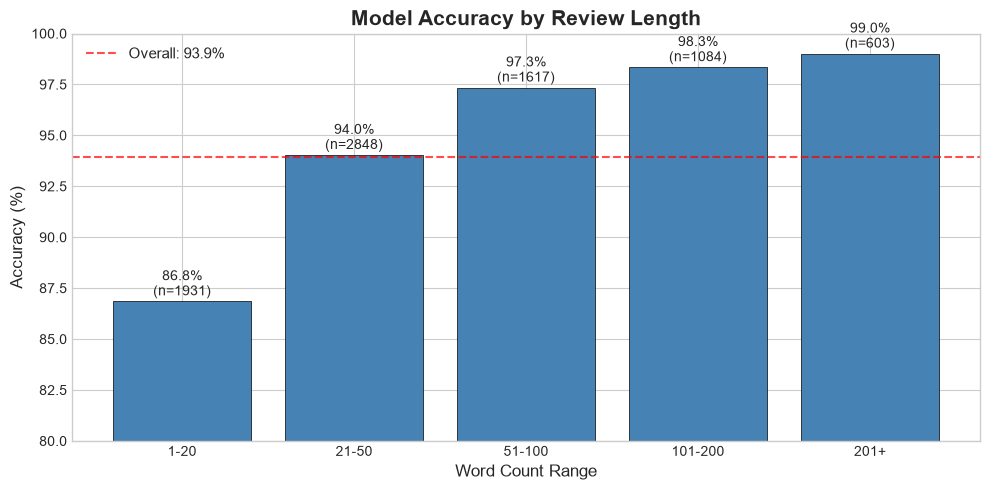

In [15]:
# ── Visualization ──
fig, ax = plt.subplots(figsize=(10, 5))

acc_by_length = df_test.groupby('length_bin', observed=False)['correct'].mean() * 100
count_by_length = df_test.groupby('length_bin', observed=False).size()

bars = ax.bar(acc_by_length.index.astype(str), acc_by_length.values,
              color='steelblue', edgecolor='black', linewidth=0.5)
ax.set_title('Model Accuracy by Review Length', fontsize=15, fontweight='bold')
ax.set_xlabel('Word Count Range', fontsize=12)
ax.set_ylabel('Accuracy (%)', fontsize=12)
ax.set_ylim(80, 100)
ax.axhline(y=accuracy*100, color='red', linestyle='--', alpha=0.7, label=f'Overall: {accuracy*100:.1f}%')
ax.legend(fontsize=11)

for bar, acc, cnt in zip(bars, acc_by_length.values, count_by_length.values):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.3,
            f'{acc:.1f}%\n(n={cnt})', ha='center', fontsize=10)

plt.tight_layout()
plt.show()

---

## 9. Performance by Product Category

Does the model perform equally well across all product categories?

In [16]:
print("📊 Accuracy by Product Category:\n")
cat_results = []
for cat in sorted(df_test['category'].unique()):
    subset = df_test[df_test['category'] == cat]
    acc = subset['correct'].mean() * 100
    count = len(subset)
    cat_results.append({'Category': cat, 'Count': count, 'Accuracy': f'{acc:.1f}%', 'Accuracy_num': acc})
    print(f"   {cat:>40s}: {acc:5.1f}%  ({count:,} reviews)")

cat_df = pd.DataFrame(cat_results)

📊 Accuracy by Product Category:

                                    Books_5:  93.5%  (876 reviews)
               Clothing_Shoes_and_Jewelry_5:  93.0%  (816 reviews)
                              Electronics_5:  95.2%  (768 reviews)
                         Home_and_Kitchen_5:  94.6%  (794 reviews)
                             Kindle_Store_5:  93.2%  (991 reviews)
                            Movies_and_TV_5:  92.3%  (684 reviews)
                             Pet_Supplies_5:  95.1%  (892 reviews)
                      Sports_and_Outdoors_5:  94.0%  (781 reviews)
               Tools_and_Home_Improvement_5:  95.1%  (709 reviews)
                           Toys_and_Games_5:  93.4%  (772 reviews)


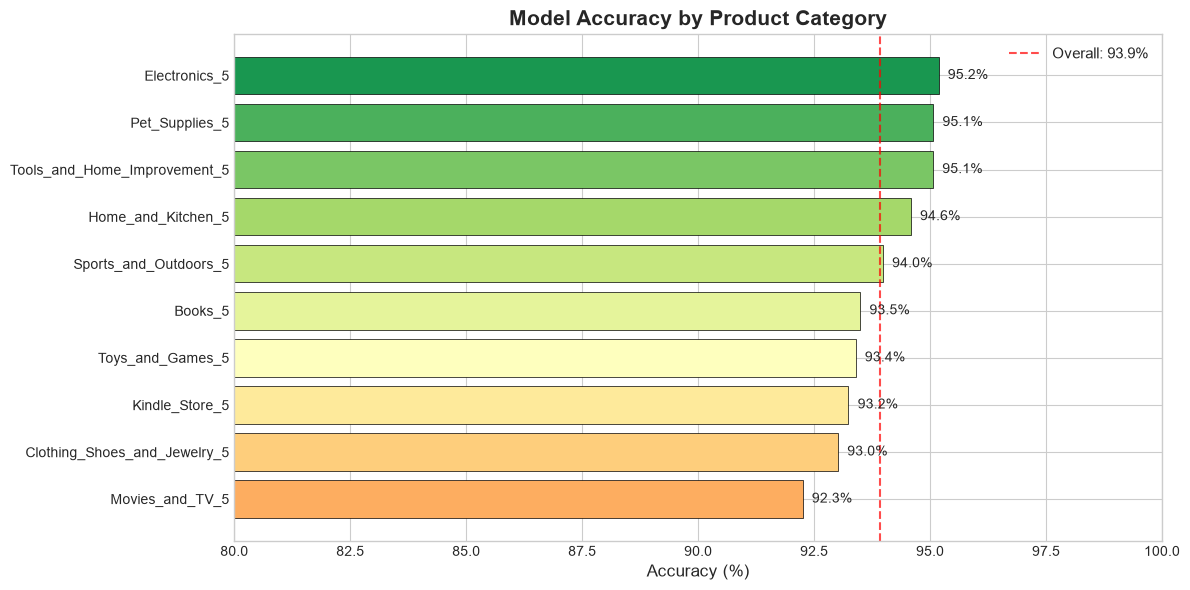

In [17]:
# ── Visualization ──
fig, ax = plt.subplots(figsize=(12, 6))

cat_df_sorted = cat_df.sort_values('Accuracy_num', ascending=True)
colors = plt.cm.RdYlGn(np.linspace(0.3, 0.9, len(cat_df_sorted)))

ax.barh(cat_df_sorted['Category'], cat_df_sorted['Accuracy_num'],
        color=colors, edgecolor='black', linewidth=0.5)
ax.axvline(x=accuracy*100, color='red', linestyle='--', alpha=0.7, label=f'Overall: {accuracy*100:.1f}%')
ax.set_title('Model Accuracy by Product Category', fontsize=15, fontweight='bold')
ax.set_xlabel('Accuracy (%)', fontsize=12)
ax.set_xlim(80, 100)
ax.legend(fontsize=11)

for i, (_, row) in enumerate(cat_df_sorted.iterrows()):
    ax.text(row['Accuracy_num'] + 0.2, i, f"{row['Accuracy_num']:.1f}%", va='center', fontsize=10)

plt.tight_layout()
plt.show()

---

## 10. Most Important Features (Words)

Logistic Regression coefficients tell us which words are most indicative of **Fake** or **Genuine** reviews.

- **Positive coefficients** → words that push toward **Fake**
- **Negative coefficients** → words that push toward **Genuine**

In [18]:
# ── Get feature names and coefficients ──
feature_names = vectorizer.get_feature_names_out()
coefficients = model.coef_[0]

# ── Top features for each class ──
n_top = 20

# Most indicative of FAKE
top_fake_idx = np.argsort(coefficients)[-n_top:][::-1]
top_fake = [(feature_names[i], coefficients[i]) for i in top_fake_idx]

# Most indicative of GENUINE
top_genuine_idx = np.argsort(coefficients)[:n_top]
top_genuine = [(feature_names[i], coefficients[i]) for i in top_genuine_idx]

print("🚨 Top 20 words indicating FAKE reviews:\n")
for word, coef in top_fake:
    print(f"   {word:25s}  coefficient: {coef:+.4f}")

print(f"\n✅ Top 20 words indicating GENUINE reviews:\n")
for word, coef in top_genuine:
    print(f"   {word:25s}  coefficient: {coef:+.4f}")

🚨 Top 20 words indicating FAKE reviews:

   the only                   coefficient: +7.1334
   will keep                  coefficient: +6.2215
   and the                    coefficient: +5.9101
   and it                     coefficient: +5.0120
   that its                   coefficient: +4.0309
   had to                     coefficient: +3.9231
   has the                    coefficient: +3.9191
   lot of                     coefficient: +3.6051
   is little                  coefficient: +3.5894
   is very                    coefficient: +3.5873
   this for                   coefficient: +3.5018
   only reason                coefficient: +3.4969
   the story                  coefficient: +3.4648
   wide                       coefficient: +3.4078
   the pieces                 coefficient: +3.3631
   had                        coefficient: +3.2424
   also                       coefficient: +3.2407
   couple                     coefficient: +3.2324
   will                       coefficient

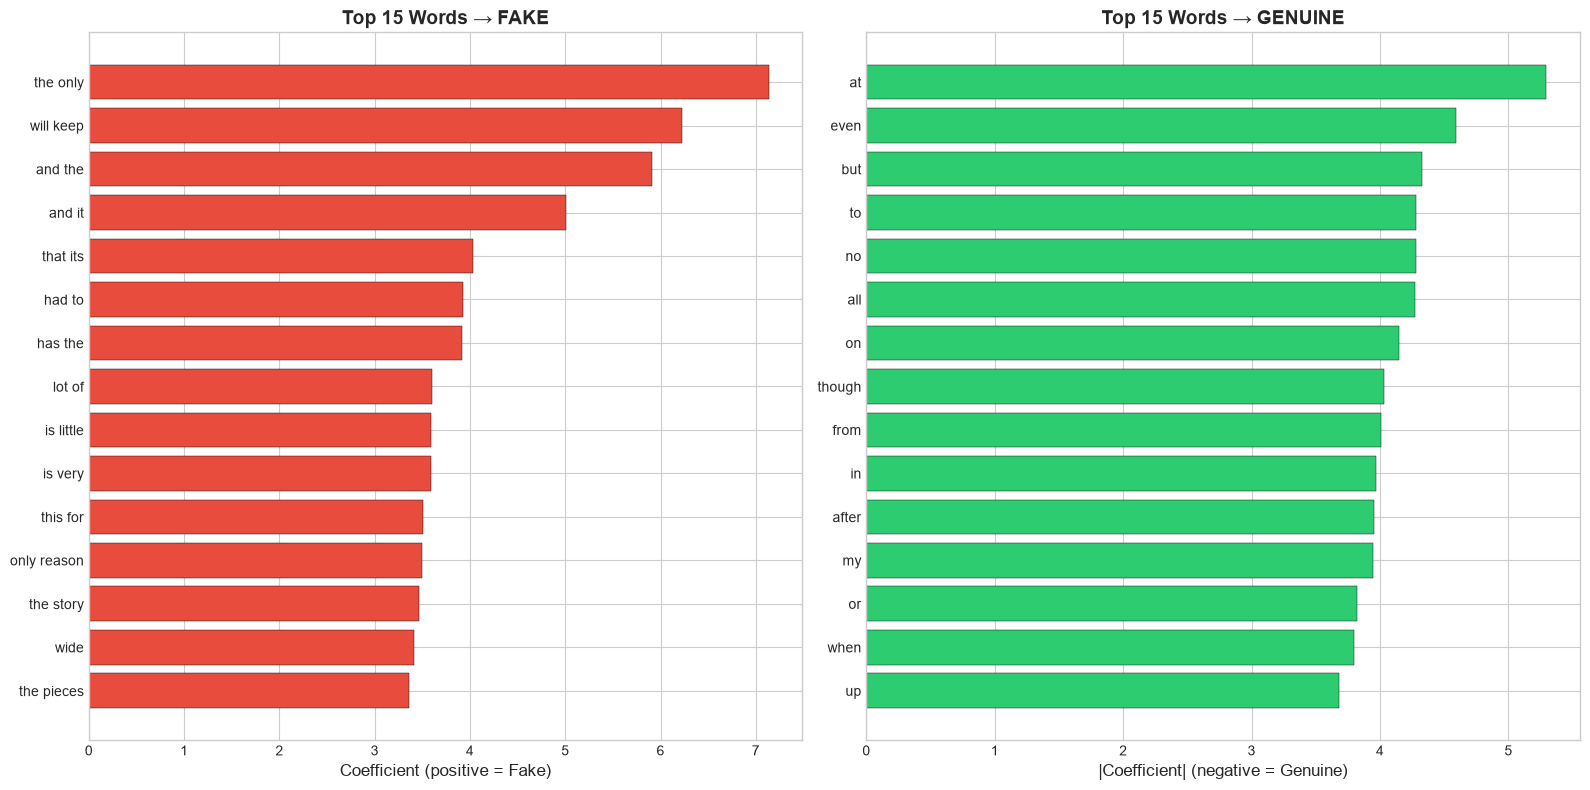

In [19]:
# ── Visualization: Top Features ──
fig, axes = plt.subplots(1, 2, figsize=(16, 8))

# Fake indicators
fake_words = [w for w, c in reversed(top_fake[:15])]
fake_coefs = [c for w, c in reversed(top_fake[:15])]
axes[0].barh(fake_words, fake_coefs, color='#e74c3c', edgecolor='black', linewidth=0.3)
axes[0].set_title('Top 15 Words → FAKE', fontsize=14, fontweight='bold')
axes[0].set_xlabel('Coefficient (positive = Fake)', fontsize=12)

# Genuine indicators
genuine_words = [w for w, c in reversed(top_genuine[:15])]
genuine_coefs = [abs(c) for w, c in reversed(top_genuine[:15])]
axes[1].barh(genuine_words, genuine_coefs, color='#2ecc71', edgecolor='black', linewidth=0.3)
axes[1].set_title('Top 15 Words → GENUINE', fontsize=14, fontweight='bold')
axes[1].set_xlabel('|Coefficient| (negative = Genuine)', fontsize=12)

plt.tight_layout()
plt.show()

---

## 11. Custom Review Testing

Test the model with your own reviews! Edit the list below and run the cell.

In [20]:
# ═══════════════════════════════════════════════════════
#  ✏️  ADD YOUR OWN REVIEWS TO TEST BELOW!
# ═══════════════════════════════════════════════════════

custom_reviews = [
    "This product is absolutely amazing and works perfectly. Best purchase ever!",
    "Terrible quality. Broke on the first day. Complete waste of money.",
    "I've been using this for three months. The battery life is good but the screen could be brighter. Overall decent for the price.",
    "Amazing amazing amazing love it so much perfect wonderful incredible best thing ever bought",
    "It arrived on time. Works as described. Nothing special but does the job.",
    "Five stars! Amazing! Perfect! Best! Love! Recommend! Buy now! Outstanding! Incredible!",
]

# ═══════════════════════════════════════════════════════

print("📊 Custom Review Predictions:\n")
results = []
for review in custom_reviews:
    cleaned = clean_text(review)
    tfidf = vectorizer.transform([cleaned])
    pred = model.predict(tfidf)[0]
    proba = model.predict_proba(tfidf)[0]
    label = 'Fake' if pred == 1 else 'Genuine'
    confidence = proba[pred] * 100
    
    emoji = '🚨' if label == 'Fake' else '✅'
    results.append({
        'Review': review[:70] + ('...' if len(review) > 70 else ''),
        'Prediction': f"{emoji} {label}",
        'Confidence': f"{confidence:.1f}%",
        'Fake %': f"{proba[1]*100:.1f}%",
        'Genuine %': f"{proba[0]*100:.1f}%",
    })

pd.DataFrame(results)

📊 Custom Review Predictions:



,Review,Prediction,Confidence,Fake %,Genuine %
0,This product is absolutely amazing and works p...,✅ Genuine,88.2%,11.8%,88.2%
1,Terrible quality. Broke on the first day. Comp...,✅ Genuine,67.2%,32.8%,67.2%
2,I've been using this for three months. The bat...,✅ Genuine,63.8%,36.2%,63.8%
3,Amazing amazing amazing love it so much perfec...,✅ Genuine,92.5%,7.5%,92.5%
4,It arrived on time. Works as described. Nothin...,✅ Genuine,89.1%,10.9%,89.1%
5,Five stars! Amazing! Perfect! Best! Love! Reco...,✅ Genuine,91.9%,8.1%,91.9%


---

## 12. Final Summary Report

In [21]:
print("\n" + "═" * 60)
print("  🧪 MODEL TESTING — FINAL SUMMARY REPORT")
print("═" * 60)

print(f"\n  📊 Core Metrics:")
print(f"     Accuracy:     {accuracy*100:.2f}%")
print(f"     Precision:    {precision*100:.2f}%")
print(f"     Recall:       {recall*100:.2f}%")
print(f"     F1-Score:     {f1*100:.2f}%")
print(f"     ROC AUC:      {roc_auc:.4f}")
print(f"     Avg Precision: {ap:.4f}")

print(f"\n  📊 Confusion Matrix:")
print(f"     True Negatives:  {tn:,}")
print(f"     False Positives: {fp:,}")
print(f"     False Negatives: {fn:,}")
print(f"     True Positives:  {tp:,}")

print(f"\n  📊 Error Analysis:")
print(f"     Total errors: {fp + fn:,} out of {len(y_test):,} ({(fp+fn)/len(y_test)*100:.1f}%)")
print(f"     False Positive rate: {fp/(fp+tn)*100:.2f}% (genuine flagged as fake)")
print(f"     False Negative rate: {fn/(fn+tp)*100:.2f}% (fake reviews missed)")

print(f"\n  📊 Confidence:")
print(f"     Mean confidence (correct): {df_test[df_test['correct']]['confidence'].mean():.1f}%")
print(f"     Mean confidence (wrong):   {df_test[~df_test['correct']]['confidence'].mean():.1f}%")

if accuracy >= 0.87:
    print(f"\n  ✅ TARGET MET: Accuracy {accuracy*100:.2f}% exceeds 87% target!")
else:
    print(f"\n  ⚠️  TARGET NOT MET: Accuracy {accuracy*100:.2f}% is below 87%.")

print("\n" + "═" * 60)


════════════════════════════════════════════════════════════
  🧪 MODEL TESTING — FINAL SUMMARY REPORT
════════════════════════════════════════════════════════════

  📊 Core Metrics:
     Accuracy:     93.93%
     Precision:    94.55%
     Recall:       93.22%
     F1-Score:     93.88%
     ROC AUC:      0.9840
     Avg Precision: 0.9852

  📊 Confusion Matrix:
     True Negatives:  3,826
     False Positives: 217
     False Negatives: 274
     True Positives:  3,766

  📊 Error Analysis:
     Total errors: 491 out of 8,083 (6.1%)
     False Positive rate: 5.37% (genuine flagged as fake)
     False Negative rate: 6.78% (fake reviews missed)

  📊 Confidence:
     Mean confidence (correct): 87.6%
     Mean confidence (wrong):   65.6%

  ✅ TARGET MET: Accuracy 93.93% exceeds 87% target!

════════════════════════════════════════════════════════════


---

## ✅ Testing Complete!

### Key Takeaways

1. **Core metrics** (accuracy, precision, recall, F1) show strong overall performance
2. **ROC-AUC and PR-AUC** confirm the model discriminates well between classes
3. **Error analysis** reveals which types of reviews the model struggles with
4. **Feature importance** shows what words the model uses to make decisions
5. **Category & length analysis** reveals whether performance varies by review type

### What To Do Next

- Use `predict.ipynb` or `python src/predict.py` for interactive predictions
- Run `streamlit run app.py` for the web interface
- Explore the error analysis to understand model limitations